# Section 122 -> Section 301 forced-labor: the tariff transition

The Section 122 balance-of-payments surcharge terminates at 12:01 a.m. on **July 24, 2026**
(last covered day July 23). Separately, USTR has *proposed* a Section 301 forced-labor
action on 60 economies (FR Doc 2026-11296) - provisional and staged off in the engine.

This notebook asks: **as the surcharge lapses and the labor regime takes its place, how
would U.S. tariffs change?** It builds three scenarios with the exact engine and 2024
import weights the main notebook uses, then compares them.

| | Scenario | How it is computed |
|---|---|---|
| **A** | Section 122 surcharge in force | engine at **2026-07-23** |
| **B** | 122 expired, nothing replaces it | engine at **2026-07-24**, labor staged off |
| **C** | 122 expired, 301 labor in force | engine at **2026-07-24**, labor activated |

Scenario C treats the labor action as effective the day the surcharge lapses - a
*hypothetical* alignment, since the proposed action has no effective date yet.

In [ ]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [1]:
import json
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    2,
    'axes.labelweight':  'bold',
    'axes.titleweight':  'bold',
    'axes.titlesize':    18,
    'axes.labelsize':    16,
    'xtick.labelsize':   12,
    'ytick.labelsize':   12,
    'legend.frameon':    False,
    'legend.fontsize':   12,
    'grid.alpha':        0.3,
    'grid.linestyle':    '--',
    'savefig.bbox':      'tight',
})

PALETTE = {
    'a122':  'black',        # Scenario A - Section 122 in force
    'gap':   '#8B0000',      # Scenario B - the post-expiry gap
    'labor': 'darkblue',     # Scenario C - Section 301 labor
    'up':    '#8B0000',      # tariff rises in the transition
    'down':  'darkgreen',    # tariff falls in the transition
}

# Match the main notebook's panel-construction cell exactly.
WEIGHT_YEAR = 2024

WITH_122   = '2026-07-23'    # last day the surcharge is in force
POST_122   = '2026-07-24'    # surcharge terminated 12:01 a.m.
LABOR_DATE = '2026-07-24'    # hypothetical: labor takes effect as 122 lapses

# The main notebook adds a flat pre-existing MFN baseline to its NATIONAL headline
# series (not to the per-country panel). We add it to the national averages here so
# they reconcile with the public tracker; per-country rates below exclude it, matching
# country-by-time.csv.
MFN_BASELINE = 2.3

## Load the tariff engine

Executes the main notebook's code cells up to `tariff_imports`, exactly as the other
analysis notebooks do. The forced-labor action has been **live** since Jul 23, 2026
(`LABOR_301_LIVE = True`, final Notice of Action), so this cell strips it back out and
rebuilds the **June 5 proposal** from the provisional files (`301-labor-economies.csv`
and the 1,098 unflagged codes of `301-labor-exemptions.csv`, flat cap). Scenarios A and
B then carry no labor duty, and the provisional regimes are activated by hand below for
Scenario C. For the final action, see `section301-labor-overview.ipynb`.

In [3]:
_nb = json.load(io.open('code/make-tariff-by-country-by-time.ipynb', encoding='utf-8'))

for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break

# The labor action went live on Jul 23, 2026 with the FINAL Notice of Action, so the
# loaded engine already applies it from Jul 24. This notebook models the June 5
# PROPOSAL: strip the live regimes and rebuild labor_301_regimes from the provisional
# files (provisional rates, flat cap, the 1,098 unflagged Annex A codes), exactly as
# section301-labor-overview.ipynb builds its `prov` scenario.
TARIFF_ACTIONS[:] = [a for a in TARIFF_ACTIONS
                     if 'forced-labor' not in a.get('reference', '')]
STACKED_REGIMES[:] = [r for r in STACKED_REGIMES
                      if not r['name'].startswith('Labor-301-')]

_prov_ex = pd.read_csv('./tariff-lists/301-labor-exemptions.csv', dtype={'digits': str})
_prov_un = _prov_ex[_prov_ex['scope_limitation'].fillna('') == '']
STACKED_EXEMPT_LISTS['Labor-PROV'] = {
    'hs8':  _prov_un.loc[_prov_un['digits'].str.len() == 8,  'digits'].tolist(),
    'hs10': _prov_un.loc[_prov_un['digits'].str.len() == 10, 'digits'].tolist()}

_prov_econ = pd.read_csv('./tariff-lists/301-labor-economies.csv', dtype={'cty_code': str})
labor_301_regimes = []
for _r in _prov_econ.itertuples():
    _code = str(_r.cty_code)
    if _code in ('', 'nan'):                      # untracked economy -> not in panel
        continue
    labor_301_regimes.append({
        'name': f'Labor-301-PROV-{_code}', 'authority': 'Section 301',
        'cty_code': _code, 'rate': float(_r.proposed_rate_pct),
        'effective_date': LABOR_DATE, 'scope': 'all',
        'exempt_lists': ['Labor-PROV'], 'exempt_232': True,
        'usmca_exempt': _code in ('1220', '2010'),
        'cafta_textile_exempt': _code in _CAFTA_DR_CODES,
        'net_of_mfn': False,
        'reference': 'Proposed Section 301 action, forced-labor investigations '
                     '(FR Doc 2026-11296, Jun 5 2026)',
        'description': f'{_r.proposed_rate_pct:g}% on all goods of {_r.economy} (proposal)',
    })

print(f"engine loaded - {len(TARIFF_ACTIONS)} tariff actions with the live labor action "
      f"removed; {len(labor_301_regimes)} provisional labor regimes staged")

engine loaded - 39 tariff actions with the live labor action removed; 50 provisional labor regimes staged


## Build the three scenarios

`rate(cty, date)` returns a country's import-weighted effective rate - the same
`(tariff x share)` sum the main notebook aggregates. We evaluate every panel country at
the pre- and post-expiry dates (Scenarios A and B), then append the labor regimes to the
action registry (effective `LABOR_DATE`) and re-evaluate for Scenario C.

In [4]:
_cache = {}
def _imp(cty):
    if cty not in _cache:
        _cache[cty] = load_imports(cty, year=WEIGHT_YEAR)
    return _cache[cty].copy()

def rate(cty, date):
    r = tariff_imports(_imp(cty), cty, 0.0, pd.to_datetime(date))
    return (r['tariff'] * r['share']).sum(), r['imports'].sum()

# Panel universe (top-50 non-EU + EU bloc), as the engine builds it.
_universe = (country_list[['CTY_CODE', 'CTY_NAME']]
             .dropna().drop_duplicates('CTY_CODE'))
_names = _universe.set_index('CTY_CODE')['CTY_NAME'].to_dict()

rate_A, imports = {}, {}
for _c in _names:
    try:
        rate_A[_c], imports[_c] = rate(_c, WITH_122)
    except FileNotFoundError:
        continue
rate_B = {c: rate(c, POST_122)[0] for c in rate_A}

# Activate the staged-off labor regime for Scenario C.
_labor = [dict(x) for x in labor_301_regimes]
for _x in _labor:
    _x['effective_date'] = LABOR_DATE
STACKED_REGIMES.extend(_labor)
for _x in _labor:
    TARIFF_ACTIONS.append({
        'effective_date': _x['effective_date'], 'authority': _x['authority'],
        'reference': _x['reference'], 'description': _x['description'],
        'phase': 3, 'apply': _make_stacked_apply(_x)})
rate_C = {c: rate(c, POST_122)[0] for c in rate_A}

_labor_codes = {x['cty_code'] for x in labor_301_regimes}
_rate_of = {x['cty_code']: x['rate'] for x in labor_301_regimes}
_cafta = {'2230', '2470', '2110', '2050', '2150', '2190'}
_usmca = {'1220', '2010'}

scen = pd.DataFrame([{
    'name': _names[c].title(), 'code': c,
    'imports_b': imports[c] / 1e9,
    'tier': _rate_of.get(c, np.nan),
    'A_122': rate_A[c], 'B_gap': rate_B[c], 'C_labor': rate_C[c],
    'group': ('USMCA' if c in _usmca else 'CAFTA-DR' if c in _cafta else
              'labor target' if c in _labor_codes else 'not targeted'),
} for c in rate_A])
scen['drop_122'] = scen['A_122'] - scen['B_gap']       # lost when the surcharge ends
scen['restore']  = scen['C_labor'] - scen['B_gap']     # added back by the labor duty
scen['net']      = scen['C_labor'] - scen['A_122']     # A -> C, the net transition

def natl(col):
    w = scen['imports_b']
    return (scen[col] * w).sum() / w.sum()

NAT = {k: natl(k) + MFN_BASELINE for k in ('A_122', 'B_gap', 'C_labor')}
print("National import-weighted average effective tariff "
      f"(incl. +{MFN_BASELINE}pp MFN baseline, matches the tracker)")
print(f"  A  Section 122 in force        : {NAT['A_122']:.2f}%")
print(f"  B  122 expired, no replacement : {NAT['B_gap']:.2f}%   ({NAT['B_gap']-NAT['A_122']:+.2f} pp)")
print(f"  C  122 expired + 301 labor     : {NAT['C_labor']:.2f}%   ({NAT['C_labor']-NAT['A_122']:+.2f} pp vs A)")

National import-weighted average effective tariff (incl. +2.3pp MFN baseline, matches the tracker)
  A  Section 122 in force        : 10.85%
  B  122 expired, no replacement : 7.68%   (-3.18 pp)
  C  122 expired + 301 labor     : 11.72%   (+0.86 pp vs A)


## 1. The headline - the labor duty more than replaces the surcharge

Letting the surcharge lapse would cut the import-weighted average tariff by nearly a third
(~10.8% to ~7.6%). The proposed labor duty more than refills that gap: because it charges
**12.5% where the surcharge charged 10%**, the national average lands *above* where it
started, at ~11.7% - a net increase of about **+0.9pp** over the status quo. The transition
is even more consequential *within* the distribution than in the aggregate.

Two conventions make the comparison clean. These national figures include the flat
**+2.3pp pre-existing MFN baseline** the main notebook adds to its headline series, so they
reconcile with the public tracker; the per-country rates below follow `country-by-time.csv`
and exclude it. And both regimes are put on the **same exemption basis** - the labor duty
applies only the 1,098 Section 122 *product* exemption codes and, like the Section 122
model, ignores the 546 civil-aircraft (GN 6) codes. Exempting aircraft from the labor duty
but not the surcharge would understate the labor rate for aircraft exporters (chiefly the
UK and EU) and shrink this aggregate step to ~+0.2pp.

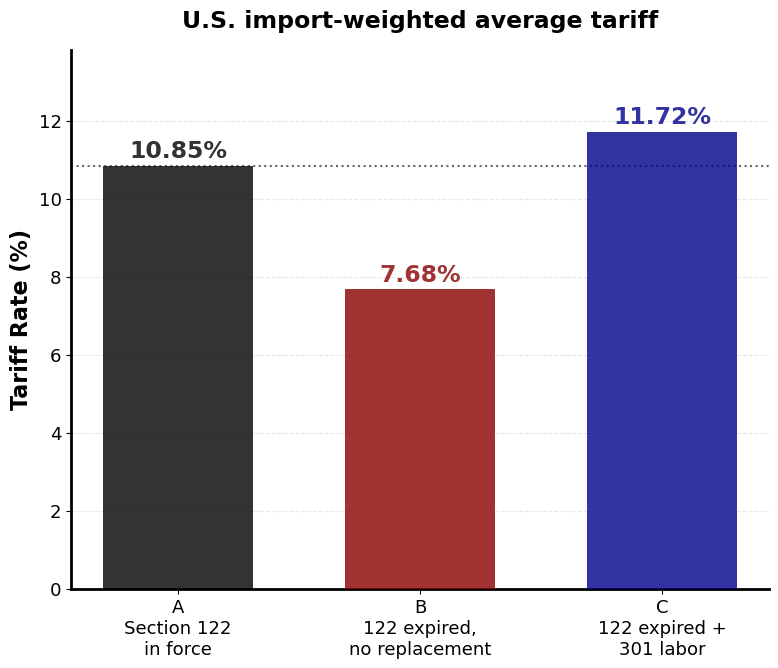

In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
order = ['A_122', 'B_gap', 'C_labor']
labels = ['A\nSection 122\nin force', 'B\n122 expired,\nno replacement',
          'C\n122 expired +\n301 labor']
colors = [PALETTE['a122'], PALETTE['gap'], PALETTE['labor']]
vals = [NAT[k] for k in order]

bars = ax.bar(labels, vals, color=colors, width=0.62, zorder=3, alpha = 0.8)
for b, v in zip(bars, vals):
    ax.annotate(f'{v:.2f}%', (b.get_x() + b.get_width()/2, v),
                xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=17, fontweight='bold', color=b.get_facecolor())
ax.axhline(NAT['A_122'], color=PALETTE['a122'], lw=1.5, ls=':', alpha=0.6, zorder=1)
ax.set_ylabel('Tariff Rate (%)')
ax.set_ylim(0, max(vals) * 1.18)
ax.set_title('U.S. import-weighted average tariff',
             fontsize=17, loc='center', pad=16)
ax.grid(axis='y'); ax.tick_params(labelsize=13)
plt.savefig(figfile + 'transition-national-average.png')
plt.savefig(figfile + 'transition-national-average.pdf')
plt.show()

## 2. The redistribution - who pays more, who pays less

Net change from Scenario A to C, country by country. Above zero, the 12.5% labor duty more
than replaces the 10% surcharge. Below zero, the labor regime lands *lighter* than the
surcharge did - either because the country sits in the 10% tier, or because a country-level
carve-out (USMCA, CAFTA-DR textiles) shields goods the surcharge reached.

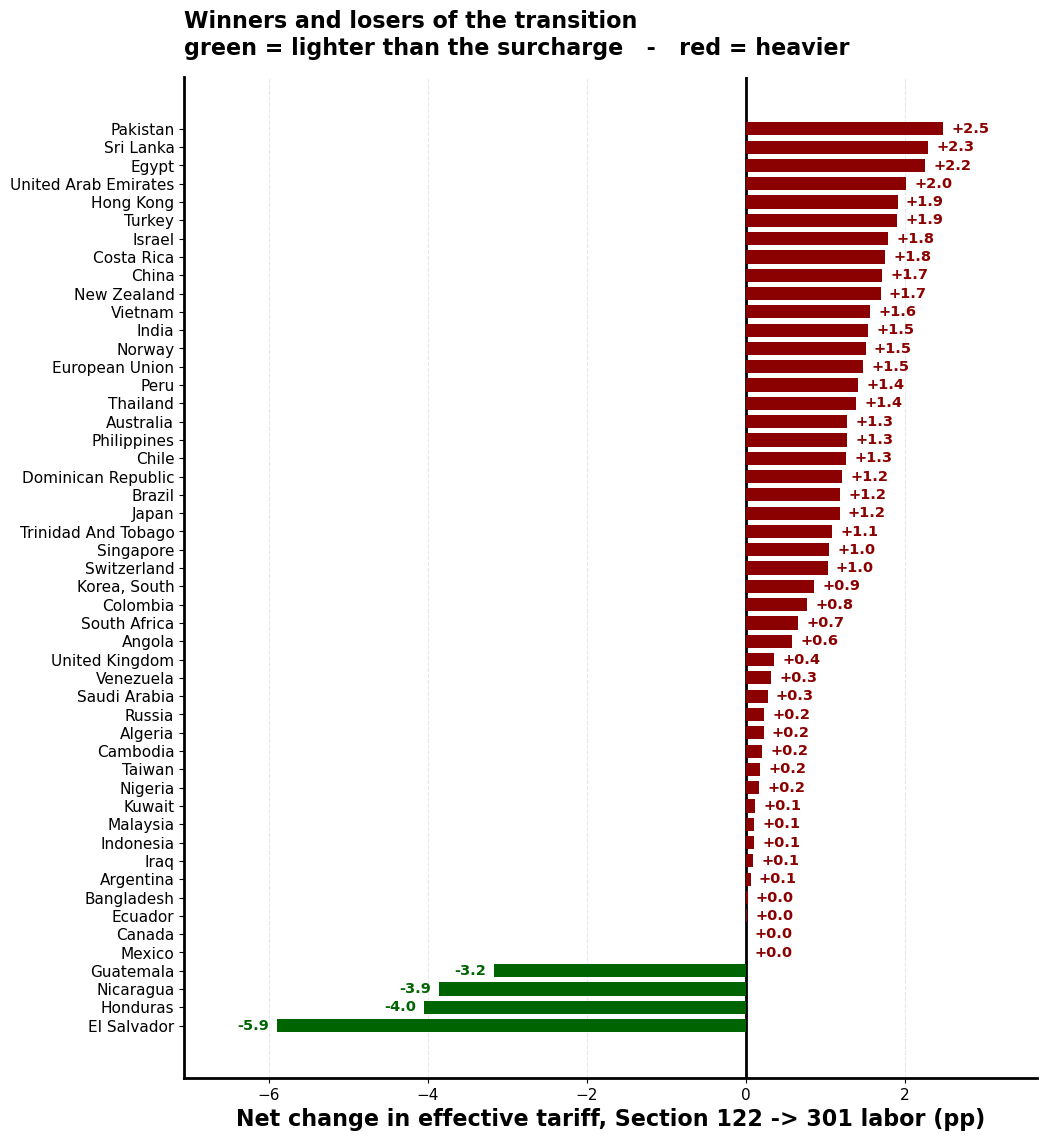

In [6]:
d = scen[scen['group'] != 'not targeted'].sort_values('net')
colors = [PALETTE['down'] if x < 0 else PALETTE['up'] for x in d['net']]

fig, ax = plt.subplots(figsize=(11, 13))
ax.barh(d['name'], d['net'], color=colors, zorder=3, height=0.72)
ax.axvline(0, color='black', lw=2)
for yi, v in enumerate(d['net']):
    ax.annotate(f'{v:+.1f}', (v, yi), xytext=(6 if v >= 0 else -6, 0),
                textcoords='offset points', va='center',
                ha='left' if v >= 0 else 'right', fontsize=10.5,
                fontweight='bold', color=(PALETTE['up'] if v >= 0 else PALETTE['down']))
ax.set_xlabel('Net change in effective tariff, Section 122 -> 301 labor (pp)')
ax.set_title('Winners and losers of the transition\n'
             'green = lighter than the surcharge   -   red = heavier',
             fontsize=16, loc='left', pad=16)
ax.margins(x=0.14); ax.grid(axis='x'); ax.tick_params(labelsize=11)
plt.savefig(figfile + 'transition-net-change.png')
plt.savefig(figfile + 'transition-net-change.pdf')
plt.show()

## 3. The two-step, for the largest suppliers

Each country drops from **A** (surcharge, black) to **B** (the post-expiry gap, red), then
the labor duty lifts it to **C** (blue). The distance A->B is what the surcharge was worth;
B->C is what the labor duty adds back. Where blue sits above black, the labor duty
overshoots the surcharge; where it sits below, it under-replaces it.

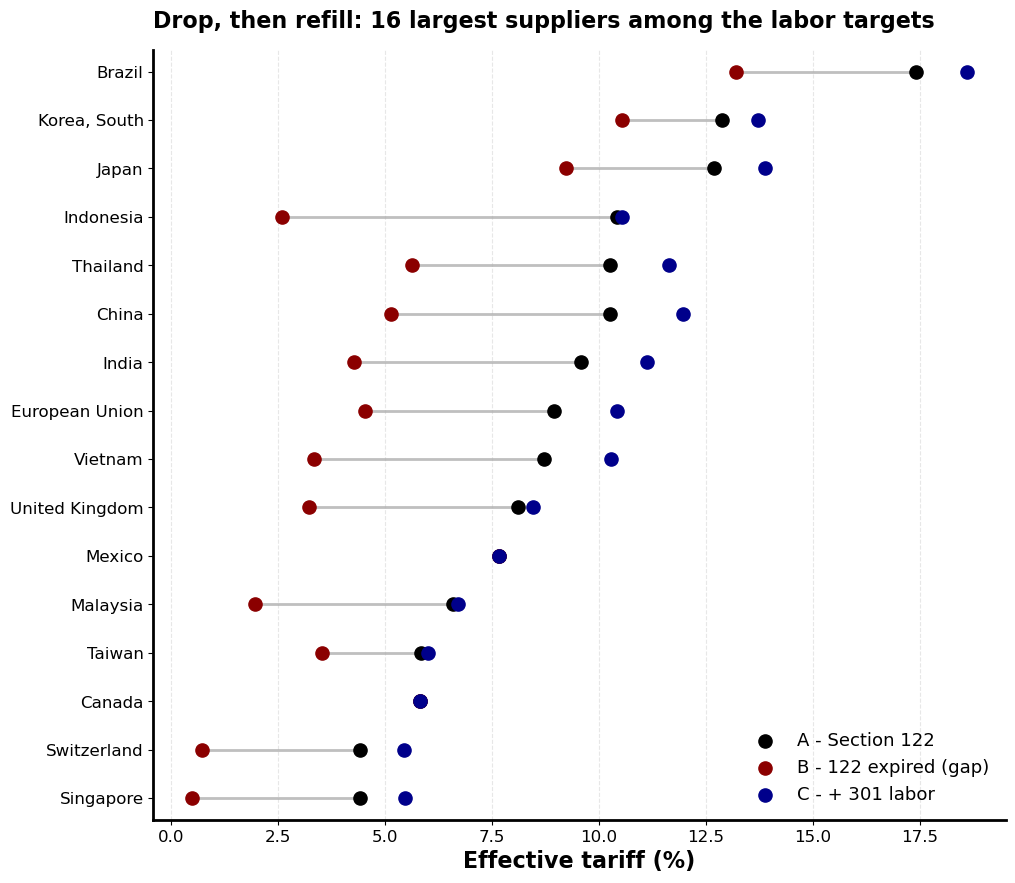

In [7]:
top = scen[scen['group'] != 'not targeted'].nlargest(16, 'imports_b').sort_values('A_122')
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(11, 10))
for yi, (_, r) in zip(y, top.iterrows()):
    ax.plot([r['B_gap'], r['A_122']], [yi, yi], color='0.75', lw=2, zorder=1)
ax.scatter(top['A_122'], y, s=90, color=PALETTE['a122'], zorder=3, label='A - Section 122')
ax.scatter(top['B_gap'], y, s=90, color=PALETTE['gap'], zorder=3, label='B - 122 expired (gap)')
ax.scatter(top['C_labor'], y, s=90, color=PALETTE['labor'], zorder=4, label='C - + 301 labor')
ax.set_yticks(y); ax.set_yticklabels(top['name'])
ax.set_xlabel('Effective tariff (%)')
ax.set_title('Drop, then refill: 16 largest suppliers among the labor targets',
             fontsize=16, loc='left', pad=16)
ax.legend(loc='lower right', fontsize=13); ax.grid(axis='x'); ax.tick_params(labelsize=12)
ax.margins(y=0.03)
plt.savefig(figfile + 'transition-dumbbell.png')
plt.savefig(figfile + 'transition-dumbbell.pdf')
plt.show()

## 4. Two carve-outs drive most of the redistribution

**CAFTA-DR textiles.** The labor Annex A exempts duty-free textiles and apparel from the
six CAFTA-DR members. Modeled flat over chapters 50-63, the relief accrues to whichever
members are apparel-heavy: El Salvador, Honduras, Nicaragua and Guatemala fall sharply,
because apparel dominates their exports and they escape the labor duty on it. The more
diversified members (Dominican Republic, Costa Rica) net slightly *up* like most countries.
The chart isolates the natural experiment - apparel exporters *with* CAFTA-DR access fall
sharply. Among those *without* it, the outcome then splits by tier: the 12.5%-tier
exporters (Sri Lanka, Pakistan) rise, while the two that earned the 10% tier through forced-
labor commitments (Bangladesh, Cambodia) stay roughly flat, moving 10% surcharge to 10%
labor. So an apparel exporter avoids an increase only via CAFTA-DR access *or* a labor
commitment; those with neither pay more.

**USMCA.** Canada and Mexico are labor targets on paper, but the model treats all their
trade as USMCA-compliant and Annex A exempts USMCA goods, so their rate does not move.
Flagged for revisit - real compliance is below 100%.

All six CAFTA-DR members (textiles/apparel exempt under Annex A):
              name A_122 C_labor   net
       El Salvador 10.28    4.38 -5.89
          Honduras 11.54    7.49 -4.05
         Nicaragua  9.69    5.83 -3.86
         Guatemala  6.72    3.55 -3.17
Dominican Republic 10.17   11.38 +1.21
        Costa Rica  7.95    9.70 +1.75

USMCA (unchanged - whole-country exemption):
  name A_122 C_labor   net
Mexico  7.66    7.66 +0.00
Canada  5.82    5.82 +0.00


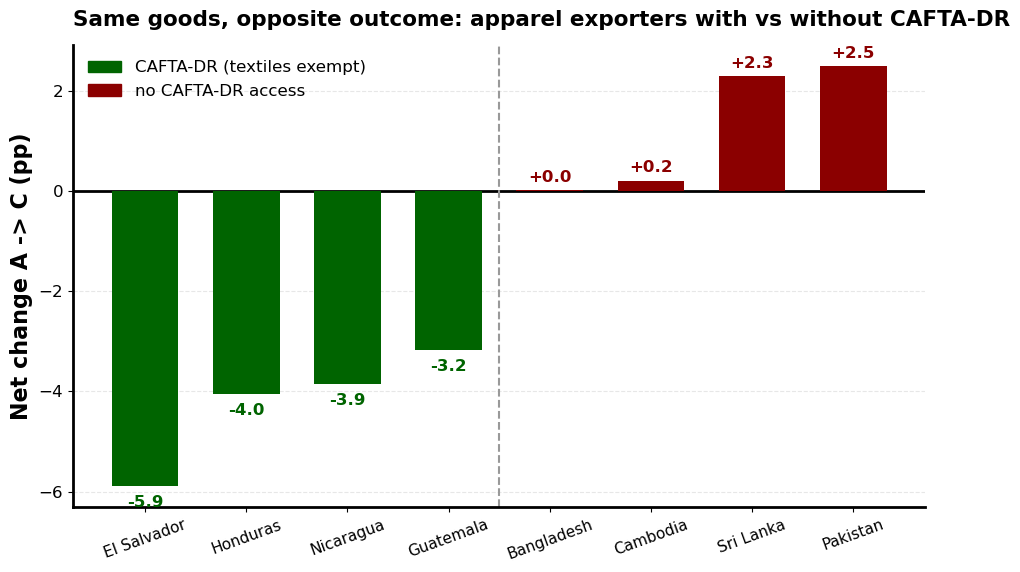

In [8]:
cafta = scen[scen['group'] == 'CAFTA-DR'].sort_values('net')
usmca = scen[scen['group'] == 'USMCA']
# The natural experiment: apparel-heavy exporters, with vs without CAFTA-DR access.
apparel_cafta = scen[scen['name'].isin(['El Salvador', 'Honduras', 'Nicaragua', 'Guatemala'])].sort_values('net')
apparel_nc = scen[scen['name'].isin(['Bangladesh', 'Cambodia', 'Sri Lanka', 'Pakistan'])].sort_values('net')
fmt = {'A_122': '{:.2f}'.format, 'C_labor': '{:.2f}'.format, 'net': '{:+.2f}'.format}

print("All six CAFTA-DR members (textiles/apparel exempt under Annex A):")
print(cafta[['name', 'A_122', 'C_labor', 'net']].to_string(index=False, formatters=fmt))
print("\nUSMCA (unchanged - whole-country exemption):")
print(usmca[['name', 'A_122', 'C_labor', 'net']].to_string(index=False, formatters=fmt))

fig, ax = plt.subplots(figsize=(11, 6))
grp = pd.concat([apparel_cafta, apparel_nc])
gcol = [PALETTE['down']] * len(apparel_cafta) + [PALETTE['up']] * len(apparel_nc)
ax.bar(grp['name'], grp['net'], color=gcol, zorder=3, width=0.66)
ax.axhline(0, color='black', lw=2)
ax.axvline(len(apparel_cafta) - 0.5, color='0.6', lw=1.5, ls='--')
for x, v in enumerate(grp['net']):
    ax.annotate(f'{v:+.1f}', (x, v), xytext=(0, 6 if v >= 0 else -15),
                textcoords='offset points', ha='center', fontsize=12, fontweight='bold',
                color=(PALETTE['up'] if v >= 0 else PALETTE['down']))
ax.set_ylabel('Net change A -> C (pp)')
ax.set_title('Same goods, opposite outcome: apparel exporters with vs without CAFTA-DR',
             fontsize=15.5, loc='left', pad=14)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETTE['down'], label='CAFTA-DR (textiles exempt)'),
                   Patch(color=PALETTE['up'], label='no CAFTA-DR access')], loc='upper left')
ax.grid(axis='y'); ax.tick_params(axis='x', labelsize=11, rotation=20)
plt.savefig(figfile + 'transition-cafta-textiles.png')
plt.savefig(figfile + 'transition-cafta-textiles.pdf')
plt.show()

## 5. Summary and caveats

- **In aggregate the labor duty more than replaces the surcharge.** The national
  import-weighted average moves from ~10.8% to ~11.7% across the transition - a net **+0.9pp**
  over the status quo - after dipping to ~7.6% in the gap if nothing replaced it. The
  increase is the 10% -> 12.5% rate step on the major 12.5%-tier partners (China, the EU,
  India, Vietnam...). (These include the +2.3pp MFN baseline and match the tracker;
  per-country rates below exclude it, per `country-by-time.csv`.)
- **Aircraft are treated as under Section 122.** Both regimes exempt the same 1,098 product
  codes; neither applies the 546 civil-aircraft (GN 6) codes - matching the Section 122
  model's existing choice - so the two are compared on the same basis. Recorded here because
  it materially affects aircraft exporters (the UK and EU) and the size of the aggregate step.
- **The action redistributes far more than it aggregates.** 12.5%-tier countries pay more
  than under the 10% surcharge; 10%-tier countries and those with country-level carve-outs
  pay less.
- **The CAFTA-DR textile carve-out is applied flat over chapters 50-63** for the six
  members and **over-exempts** - it frees textile trade regardless of whether it actually
  claimed CAFTA-DR duty-free treatment. It is the single largest source of relief in the
  transition.
- **USMCA zeroes Canada and Mexico** under the model's all-compliant simplification;
  flagged for revisit.
- **The whole labor action is provisional.** FR Doc 2026-11296 is a determination and a
  *proposed* action with no effective date; Scenario C dates it to the surcharge's expiry
  as an illustrative alignment. When a Notice of Action issues, run
  `validate-301-labor.py --diff-*` and re-run this notebook.

## 6. The two exemption annexes cover identical imports

We know the code lists are identical; this is the visual. The Section 122 surcharge and the
Section 301 labor action carve out goods through separate legal instruments - the surcharge's
**Proclamation Annex I** and the labor notice's **Annex A** - but the two enumerate the same
HTSUS codes. Each bar below is computed *independently from its own source files* (the
`section122-*` lists for 122, `301-labor-exemptions.csv` for 301), not by reusing one number
twice, and they land on the same share of U.S. imports.

(Full annexes, 1,655 codes each, including the civil-aircraft codes; the tariff engine applies
a product-only subset of both, per the aircraft note in Section 1.)

{'Section 122 surcharge (Proclamation Annex I)': np.float64(43.1), 'Section 301 forced labor (Annex A)': np.float64(43.1)}


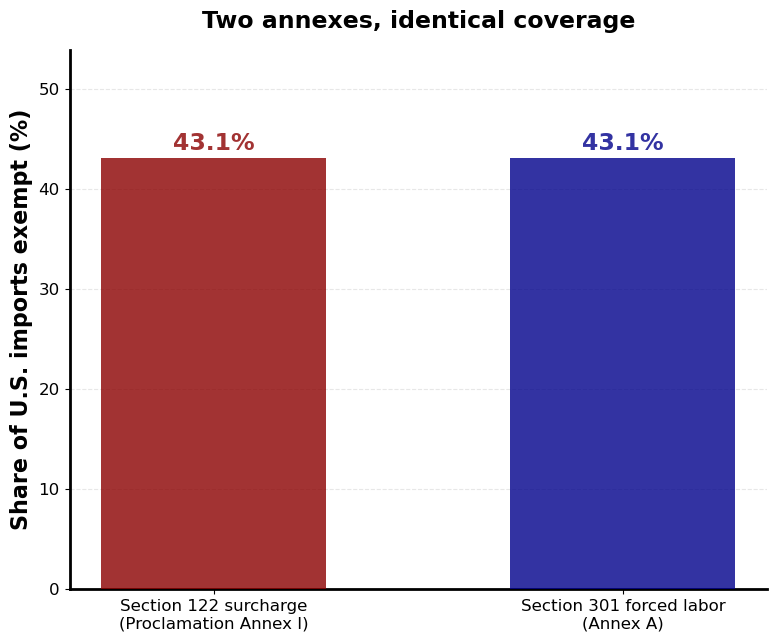

In [9]:
# Two INDEPENDENT sources: Section 122 from its three exemption files, Section 301 from Annex A.
def _split(series):
    s = series.astype(str)
    return set(s[s.str.len() == 8]), set(s[s.str.len() == 10])

_s122 = pd.concat([pd.read_csv(f'tariff-lists/section122-{k}-exemptions.csv', dtype=str)
                   for k in ('product', 'aircraft', 'specific')])
_s122_8, _s122_10 = _split(_s122['hts_code'])
_annexA = pd.read_csv('tariff-lists/301-labor-exemptions.csv', dtype=str)
_annexA_8, _annexA_10 = _split(_annexA['digits'])

def _exempt_share(h8, h10):
    ex = tot = 0.0
    for _c in scen['code']:                      # every panel country, 2024 imports
        d = _imp(_c)
        m = d['HS8'].isin(h8) | d['HS10'].isin(h10)
        ex += d.loc[m, 'imports'].sum(); tot += d['imports'].sum()
    return 100 * ex / tot

_labels = ['Section 122 surcharge' + chr(10) + '(Proclamation Annex I)',
           'Section 301 forced labor' + chr(10) + '(Annex A)']
_vals = [_exempt_share(_s122_8, _s122_10), _exempt_share(_annexA_8, _annexA_10)]
print(dict(zip([l.replace(chr(10), ' ') for l in _labels], [round(v, 2) for v in _vals])))

fig, ax = plt.subplots(figsize=(9, 7))
bars = ax.bar(_labels, _vals, color=[PALETTE['gap'], PALETTE['labor']],
              width=0.55, zorder=3, alpha=0.8)
for b, v in zip(bars, _vals):
    ax.annotate(f'{v:.1f}%', (b.get_x() + b.get_width() / 2, v),
                xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=17, fontweight='bold', color=b.get_facecolor())
ax.set_ylabel('Share of U.S. imports exempt (%)')
ax.set_ylim(0, max(_vals) * 1.25)
ax.set_title('Two annexes, identical coverage', fontsize=17, loc='center', pad=16)
ax.grid(axis='y'); ax.tick_params(labelsize=12)
plt.savefig(figfile + 'transition-exempt-share.png')
plt.savefig(figfile + 'transition-exempt-share.pdf')
plt.show()